In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

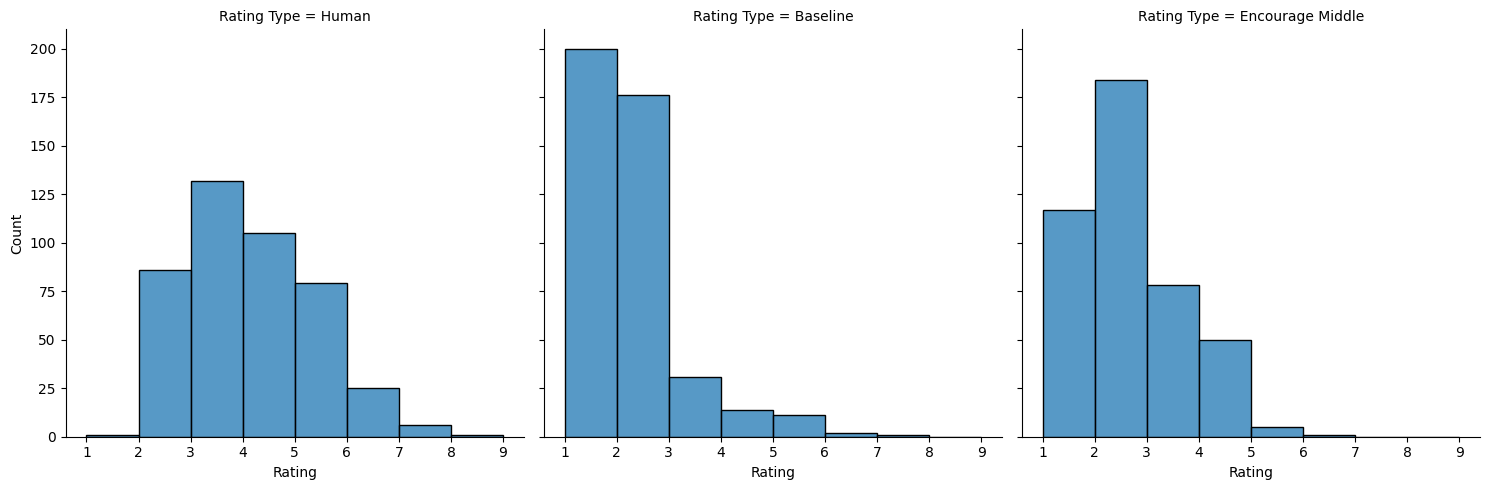

In [2]:
encourage_middle2 = pd.read_csv(
    "output/encourage_middle2/similarities.csv", index_col=0
)
baseline = pd.read_csv("output/baseline/similarities.csv", index_col=0)

baseline.rename(
    columns={
        "Human Rating": "Human",
        "ChatGPT Rating": "Baseline",
    },
    inplace=True,
)

encourage_middle2.rename(
    columns={
        "Human Rating": "Human",
        "ChatGPT Rating": "Encourage Middle",
    },
    inplace=True,
)

mrg = baseline.merge(
    encourage_middle2, on=["Rock1", "Rock2", "Rock1 Index", "Rock2 Index", "Human"]
)

mlt = mrg.melt(
    id_vars=["Rock1", "Rock2"],
    value_vars=["Human", "Baseline", "Encourage Middle"],
    var_name="Rating Type",
    value_name="Rating",
)

sns.displot(
    data=mlt,
    x="Rating",
    col="Rating Type",
    kind="hist",
    bins=[1, 2, 3, 4, 5, 6, 7, 8, 9],
    facet_kws={"sharey": True, "sharex": True},
)
plt.savefig("output/figures/prompt_comparison_30.png", bbox_inches="tight")
plt.savefig("output/figures/prompt_comparison_30.pdf", bbox_inches="tight")

In [3]:
baseline360 = pd.read_csv("output/baseline_360/similarities.csv", index_col=0)
encourage_middle_360 = pd.read_csv(
    "output/encourage_middle_360/similarities.csv", index_col=0
)
baseline360.rename(
    columns={
        "Human Rating": "Human",
        "ChatGPT Rating": "Baseline",
    },
    inplace=True,
)

encourage_middle_360.rename(
    columns={
        "Human Rating": "Human",
        "ChatGPT Rating": "Encourage Middle",
    },
    inplace=True,
)

mrg = baseline360.merge(
    encourage_middle_360, on=["Rock1", "Rock2", "Rock1 Index", "Rock2 Index", "Human"]
)

In [4]:
baseline360["Rock1 Category"] = baseline360["Rock1"].str.split("_").str[1]
baseline360["Rock2 Category"] = baseline360["Rock2"].str.split("_").str[1]
baseline360["Comparison"] = (
    baseline360["Rock1 Category"] + " vs " + baseline360["Rock2 Category"]
)
comparison_baseline = (
    baseline360.groupby("Comparison")[["Human", "Baseline"]].mean().reset_index()
)

In [5]:
encourage_middle_360["Rock1 Category"] = (
    encourage_middle_360["Rock1"].str.split("_").str[1]
)
encourage_middle_360["Rock2 Category"] = (
    encourage_middle_360["Rock2"].str.split("_").str[1]
)
encourage_middle_360["Comparison"] = (
    encourage_middle_360["Rock1 Category"]
    + " vs "
    + encourage_middle_360["Rock2 Category"]
)
comparison_encourage_middle = (
    encourage_middle_360.groupby("Comparison")[["Human", "Encourage Middle"]]
    .mean()
    .reset_index()
)

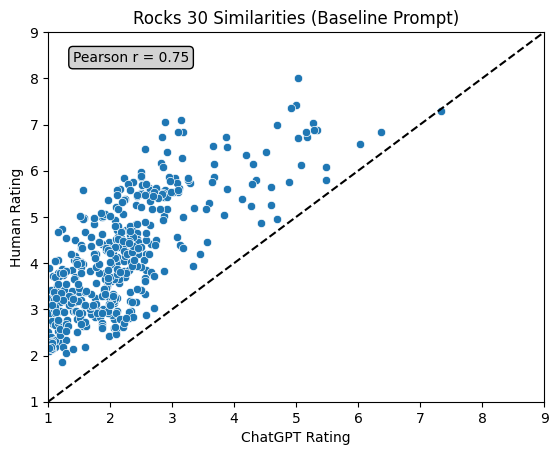

In [6]:
sns.scatterplot(
    data=baseline,
    x="Baseline",
    y="Human",
)
plt.plot([1, 9], [1, 9], "k--")
plt.xlim(1, 9)
plt.ylim(1, 9)
plt.xlabel("ChatGPT Rating")
plt.ylabel("Human Rating")
plt.title("Rocks 30 Similarities (Baseline Prompt)")
plt.annotate(
    f"Pearson r = {baseline['Baseline'].corr(baseline['Human']):.2f}",
    xy=(0.05, 0.95),
    xycoords="axes fraction",
    ha="left",
    va="top",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="lightgray"),
)
plt.savefig(
    "output/figures/individual_scatterplot_30_baseline.pdf", bbox_inches="tight"
)
plt.savefig(
    "output/figures/individual_scatterplot_30_baseline.png", bbox_inches="tight"
)

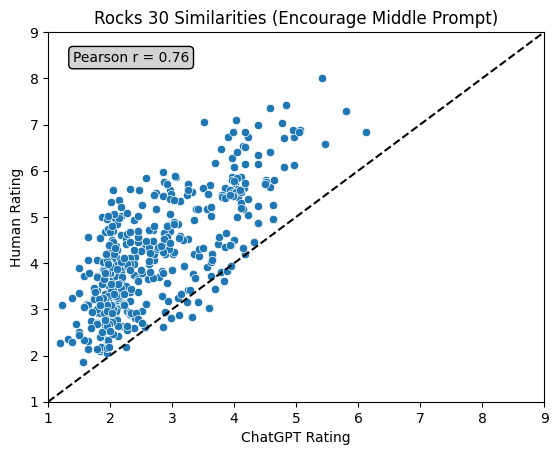

In [7]:
sns.scatterplot(
    data=encourage_middle2,
    x="Encourage Middle",
    y="Human",
)
plt.plot([1, 9], [1, 9], "k--")
plt.xlim(1, 9)
plt.ylim(1, 9)
plt.xlabel("ChatGPT Rating")
plt.ylabel("Human Rating")
plt.title("Rocks 30 Similarities (Encourage Middle Prompt)")
plt.annotate(
    f"Pearson r = {encourage_middle2['Encourage Middle'].corr(encourage_middle2['Human']):.2f}",
    xy=(0.05, 0.95),
    xycoords="axes fraction",
    ha="left",
    va="top",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="lightgray"),
)
plt.savefig(
    "output/figures/individual_scatterplot_30_encourage_middle.pdf", bbox_inches="tight"
)
plt.savefig(
    "output/figures/individual_scatterplot_30_encourage_middle.png", bbox_inches="tight"
)

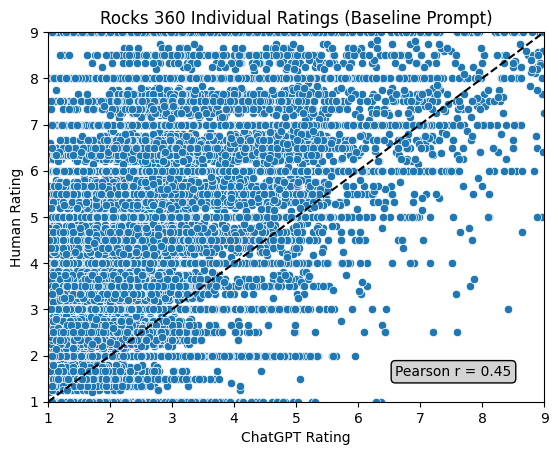

In [8]:
sns.scatterplot(
    data=baseline360,
    x="Baseline",
    y="Human",
)
plt.plot([1, 9], [1, 9], "k--")
plt.xlim(1, 9)
plt.ylim(1, 9)
plt.xlabel("ChatGPT Rating")
plt.ylabel("Human Rating")
plt.title("Rocks 360 Individual Ratings (Baseline Prompt)")
plt.annotate(
    f"Pearson r = {baseline360['Baseline'].corr(baseline360['Human']):.2f}",
    xy=(0.7, 0.1),
    xycoords="axes fraction",
    ha="left",
    va="top",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="lightgray"),
)
plt.savefig(
    "output/figures/individual_scatterplot_360_baseline.pdf", bbox_inches="tight"
)
plt.savefig(
    "output/figures/individual_scatterplot_360_baseline.png", bbox_inches="tight"
)

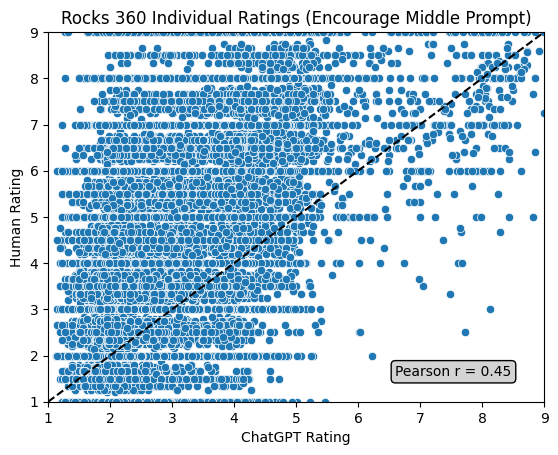

In [9]:
sns.scatterplot(
    data=encourage_middle_360,
    x="Encourage Middle",
    y="Human",
)
plt.plot([1, 9], [1, 9], "k--")
plt.xlim(1, 9)
plt.ylim(1, 9)
plt.xlabel("ChatGPT Rating")
plt.ylabel("Human Rating")
plt.title("Rocks 360 Individual Ratings (Encourage Middle Prompt)")
plt.annotate(
    f"Pearson r = {encourage_middle_360['Encourage Middle'].corr(baseline360['Human']):.2f}",
    xy=(0.7, 0.1),
    xycoords="axes fraction",
    ha="left",
    va="top",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="lightgray"),
)
plt.savefig(
    "output/figures/individual_scatterplot_360_encourage_middle.pdf",
    bbox_inches="tight",
)
plt.savefig(
    "output/figures/individual_scatterplot_360_encourage_middle.png",
    bbox_inches="tight",
)

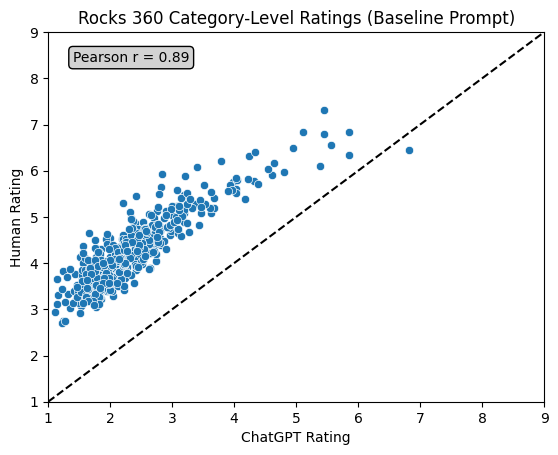

In [10]:
sns.scatterplot(
    data=comparison_baseline,
    x="Baseline",
    y="Human",
)
plt.plot([1, 9], [1, 9], "k--")
plt.xlim(1, 9)
plt.ylim(1, 9)
plt.xlabel("ChatGPT Rating")
plt.ylabel("Human Rating")
plt.title("Rocks 360 Category-Level Ratings (Baseline Prompt)")
plt.annotate(
    f"Pearson r = {comparison_baseline['Baseline'].corr(comparison_baseline['Human']):.2f}",
    xy=(0.05, 0.95),
    xycoords="axes fraction",
    ha="left",
    va="top",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="lightgray"),
)
plt.savefig("output/figures/category_scatterplot_360_baseline.png", bbox_inches="tight")
plt.savefig("output/figures/category_scatterplot_360_baseline.pdf", bbox_inches="tight")

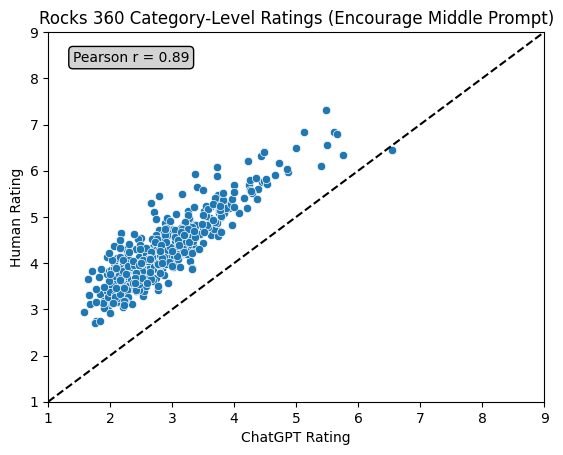

In [11]:
sns.scatterplot(
    data=comparison_encourage_middle,
    x="Encourage Middle",
    y="Human",
)
plt.plot([1, 9], [1, 9], "k--")
plt.xlim(1, 9)
plt.ylim(1, 9)
plt.xlabel("ChatGPT Rating")
plt.ylabel("Human Rating")
plt.title("Rocks 360 Category-Level Ratings (Encourage Middle Prompt)")
plt.annotate(
    f"Pearson r = {comparison_encourage_middle['Encourage Middle'].corr(comparison_encourage_middle['Human']):.2f}",
    xy=(0.05, 0.95),
    xycoords="axes fraction",
    ha="left",
    va="top",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="lightgray"),
)
plt.savefig(
    "output/figures/category_scatterplot_360_encourage_middle.png", bbox_inches="tight"
)
plt.savefig(
    "output/figures/category_scatterplot_360_encourage_middle.pdf", bbox_inches="tight"
)